# 03 · Saddle-node bifurcation, closed form

The peak of the conservation curve `Γ(Λ)` is a **saddle-node (fold) bifurcation**: as the
fresh rate `λ` rises to `λ_crit`, the stable and unstable fixed points move toward each
other and merge. For single-node queues the fold has an exact solution.

For Case 2, setting `Γ'(Λ) = 0` and writing `v = 1 + ΛT` gives `v·eᵛ = e^(μT+1)`, so

$$v = W_0\!\left(e^{\mu T+1}\right) = \omega(\mu T+1),\qquad
\Lambda_{SN} = \frac{v-1}{T},\qquad
\lambda_{crit} = (1-p)\,\frac{(v-1)^2}{T\,v}.$$

`W₀` is the principal Lambert-W branch and `ω` the Wright-omega function.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

import aqnet

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
print("aqnet", aqnet.__version__)

aqnet 0.3.0


## Wright-omega and Lambert-W₀ agree

`fold_parameter_v` uses Wright-omega by default because Lambert-W needs `e^(μT+1)`, which
overflows double precision once `μT > 708`.

In [2]:
print(f"{'μT':>8}{'ω(μT+1)':>16}{'W0(e^(μT+1))':>16}{'|diff|':>11}{'v+ln v-(μT+1)':>16}")
for muT in (0.1, 1.0, 10.0, 100.0, 700.0, 5000.0):
    v = aqnet.fold_parameter_v(muT, 1.0)
    try:
        w = aqnet.fold_parameter_v(muT, 1.0, method="lambertw")
        diff = f"{abs(v - w):.1e}"
        w = f"{w:.10g}"
    except ValueError:
        w, diff = "overflow", "-"
    print(f"{muT:>8}{v:>16.10g}{w:>16}{diff:>11}{v + np.log(v) - (muT + 1):>16.1e}")

      μT         ω(μT+1)    W0(e^(μT+1))     |diff|   v+ln v-(μT+1)
     0.1     1.050619761     1.050619761    0.0e+00         0.0e+00
     1.0     1.557145599     1.557145599    2.2e-16        -2.2e-16
    10.0     8.822674899     8.822674899    0.0e+00         0.0e+00
   100.0     96.43117051     96.43117051    1.4e-14        -1.4e-14
   700.0     694.4568699     694.4568699    0.0e+00         0.0e+00
  5000.0     4992.484311        overflow          -         0.0e+00


## Closed form against brute-force maximisation

In [3]:
from scipy.optimize import minimize_scalar

print(f"{'case':<24}{'p':>5}{'λ_crit closed':>15}{'λ_crit numeric':>16}{'rel diff':>10}")
for topo in ("one_node_destruction", "one_node_modification"):
    for p in (0.0, 0.3, 0.6):
        sn = aqnet.solve_saddle_node_bifurcation(topo, p=p, mu=10.0, T=1.0)
        res = minimize_scalar(lambda x: -aqnet.throughput_curve_gamma(x, topo, p, 10.0, 1.0),
                              bounds=(0, sn.Lambda_max), method="bounded", options={"xatol": 1e-12})
        print(f"{topo:<24}{p:>5}{sn.lambda_crit_sn:>15.10f}{-res.fun:>16.10f}"
              f"{abs(sn.lambda_crit_sn + res.fun) / sn.lambda_crit_sn:>10.1e}")

case                        p  λ_crit closed  λ_crit numeric  rel diff
one_node_destruction      0.0   6.9360192095    6.9360192095   1.3e-16
one_node_destruction      0.3   6.9360192095    6.9360192095   0.0e+00
one_node_destruction      0.6   6.9360192095    6.9360192095   1.3e-16
one_node_modification     0.0   6.9360192095    6.9360192095   1.3e-16
one_node_modification     0.3   4.8552134467    4.8552134467   0.0e+00
one_node_modification     0.6   2.7744076838    2.7744076838   0.0e+00


## Phase portrait: two fixed points

At `λ = 3.5` the horizontal line meets `Γ` twice. Between the two crossings `Γ(Λ) > λ`:
more packets leave than arrive, so the retry load shrinks back to the stable point. Above
the separatrix `Γ(Λ) < λ` and the load keeps growing.

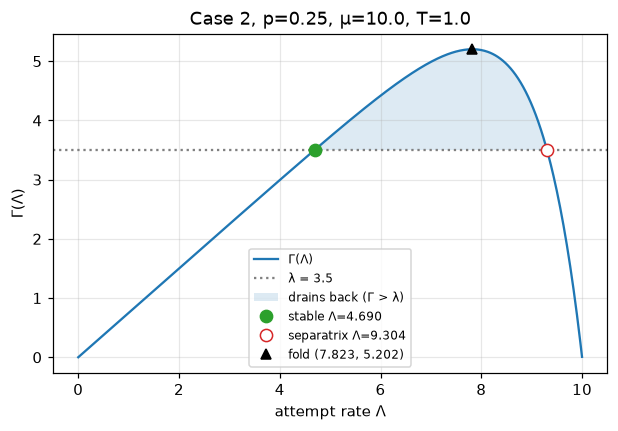

In [4]:
topo, p, mu, T, lam = "one_node_modification", 0.25, 10.0, 1.0, 3.5
sn = aqnet.solve_saddle_node_bifurcation(topo, p=p, mu=mu, T=T)
d = aqnet.solve_dual_fixed_points(lam, topo, p=p, mu=mu, T=T)
Lam = np.linspace(1e-3, sn.Lambda_max * 0.9999, 600)
g = np.array([aqnet.throughput_curve_gamma(x, topo, p, mu, T) for x in Lam])

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(Lam, g, label="Γ(Λ)")
ax.axhline(lam, color="gray", ls=":", label=f"λ = {lam}")
ax.fill_between(Lam, lam, g, where=(g > lam), alpha=0.15, label="drains back (Γ > λ)")
ax.plot(d.Lambda_stable, lam, "o", color="tab:green", ms=8, label=f"stable Λ={d.Lambda_stable:.3f}")
ax.plot(d.Lambda_unstable, lam, "o", mfc="white", color="tab:red", ms=8,
        label=f"separatrix Λ={d.Lambda_unstable:.3f}")
ax.plot(sn.Lambda_sn, sn.lambda_crit_sn, "k^", label=f"fold ({sn.Lambda_sn:.3f}, {sn.lambda_crit_sn:.3f})")
ax.set(xlabel="attempt rate Λ", ylabel="Γ(Λ)", title=f"Case 2, p={p}, μ={mu}, T={T}")
ax.legend(fontsize=8)
plt.show()

## Bifurcation diagram and the square-root normal form

Close to the fold, `Λ± ≈ Λ_SN ± √((λ_crit − λ)/c₂)` with `c₂ = −Γ''(Λ_SN)/2`. The dashed
curves are that approximation.

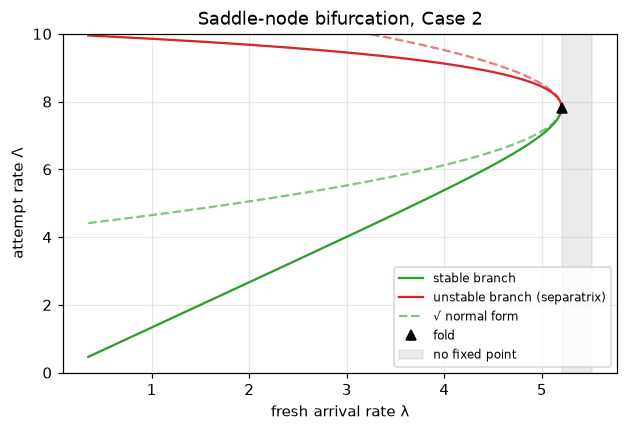

In [5]:
lams = sn.lambda_crit_sn * (1 - np.geomspace(1, 1e-6, 200))[1:]
duals = [aqnet.solve_dual_fixed_points(l, topo, p=p, mu=mu, T=T) for l in lams]
lo = [x.Lambda_stable for x in duals]; hi = [x.Lambda_unstable for x in duals]
alo = [x.sqrt_asymptotic_stable for x in duals]; ahi = [x.sqrt_asymptotic_unstable for x in duals]

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(lams, lo, color="tab:green", label="stable branch")
ax.plot(lams, hi, color="tab:red", label="unstable branch (separatrix)")
ax.plot(lams, alo, "--", color="tab:green", alpha=0.6, label="√ normal form")
ax.plot(lams, ahi, "--", color="tab:red", alpha=0.6)
ax.plot(sn.lambda_crit_sn, sn.Lambda_sn, "k^", label="fold")
ax.axvspan(sn.lambda_crit_sn, sn.lambda_crit_sn * 1.06, color="gray", alpha=0.15, label="no fixed point")
ax.set(xlabel="fresh arrival rate λ", ylabel="attempt rate Λ", ylim=(0, sn.Lambda_max),
       title="Saddle-node bifurcation, Case 2")
ax.legend(fontsize=8)
plt.show()

On log-log axes the branch gap scales with slope `+1/2` and the stable-branch
sensitivity `dΛ/dλ` with slope `−1/2`, the signature of a fold.

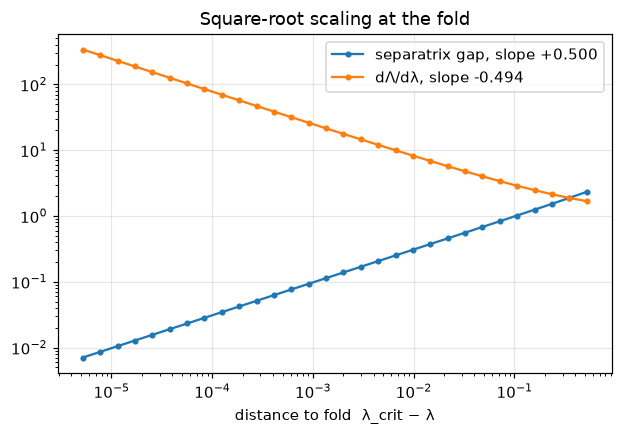

fitted slopes: gap 0.5001 (theory 0.5), sensitivity -0.4937 (theory -0.5)


In [6]:
margins = np.geomspace(1e-1, 1e-6, 30) * sn.lambda_crit_sn
ds = [aqnet.solve_dual_fixed_points(sn.lambda_crit_sn - m, topo, p=p, mu=mu, T=T) for m in margins]
gap = np.array([x.separatrix_gap for x in ds])
sens = np.array([x.delay_sensitivity_dLambda_dlambda for x in ds])
slope_gap = np.polyfit(np.log(margins[10:]), np.log(gap[10:]), 1)[0]
slope_sens = np.polyfit(np.log(margins[10:]), np.log(sens[10:]), 1)[0]

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.loglog(margins, gap, marker=".", label=f"separatrix gap, slope {slope_gap:+.3f}")
ax.loglog(margins, sens, marker=".", label=f"dΛ/dλ, slope {slope_sens:+.3f}")
ax.set(xlabel="distance to fold  λ_crit − λ", title="Square-root scaling at the fold")
ax.legend()
plt.show()
print(f"fitted slopes: gap {slope_gap:.4f} (theory 0.5), sensitivity {slope_sens:.4f} (theory -0.5)")

## How attacks move the fold

* **Destruction** (Case 1): the attacker removes packets before the server, so the server
  load is `(1 − p)Λ` and `λ_crit` does not depend on `p` at all.
* **Modification** (Case 2): wasted service shrinks `λ_crit` linearly, `(1 − p)·λ_crit(0)`.
* **Multi-node** cases (numerical fold) decay faster because each hop is attacked.

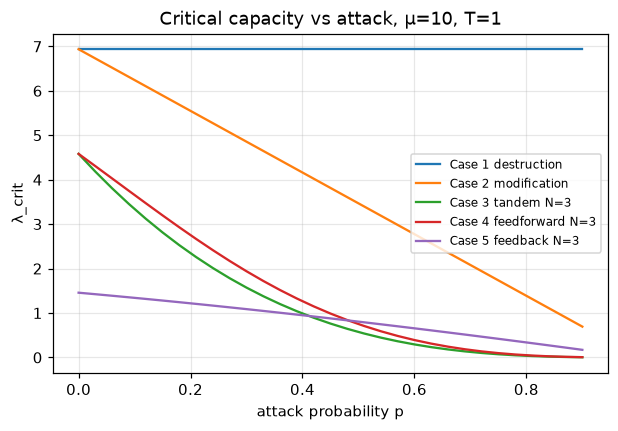

In [7]:
ps = np.linspace(0, 0.9, 31)
series = {
    "Case 1 destruction": ("one_node_destruction", 2),
    "Case 2 modification": ("one_node_modification", 2),
    "Case 3 tandem N=3": ("tandem", 3),
    "Case 4 feedforward N=3": ("feedforward", 3),
    "Case 5 feedback N=3": ("feedback", 3),
}
fig, ax = plt.subplots(figsize=(6.5, 4))
for label, (topo_i, N) in series.items():
    ax.plot(ps, [aqnet.solve_saddle_node_bifurcation(topo_i, p=pp, mu=10.0, T=1.0, N=N).lambda_crit_sn
                 for pp in ps], label=label)
ax.set(xlabel="attack probability p", ylabel="λ_crit", title="Critical capacity vs attack, μ=10, T=1")
ax.legend(fontsize=8)
plt.show()

## Symbolic verification

SymPy re-derives the stationarity identity, the curvature at the fold, Case 1
`p`-invariance and the square-root normal form.

In [8]:
proofs = aqnet.verify_symbolic_bifurcation_proofs()
for k, val in proofs.items():
    print(f"{k:<36} {val}")
assert proofs["all_symbolic_proofs_verified"]

stationarity_identity_verified       True
concavity_curvature_verified         True
destruction_p_invariance_verified    True
sqrt_normal_form_verified            True
all_symbolic_proofs_verified         True
d2Gamma_at_sn_expr                   T*(p - 1)*(v + 1)/v
gamma_dest_effective_load_expr       -x*exp(-T*mu + T*x) + x
lambertw_vs_wrightomega_abs_diff     0.0
